# Employee Attrition Prediction — Group 5_C9

Which employees are likely to leave, and what is linked to leaving?
Data: IBM HR Analytics Employee Attrition (fictional, 1,470 employees, 16% left).
Full context, team and how to run: see the repository
[README](https://github.com/Trumpibeabuchi/techcrush-c9-group5-attrition#readme).

**Hypotheses (written before the analysis):**
H1 overtime · H2 pay · H3 tenure/age · H4 satisfaction · H5 travel · H6 job role ·
H7 gender/education (control)

**Note:** units are not documented, and the data is fictional, so results are
compared in relative terms.

## 1. Setup

Libraries used throughout the notebook, and a `figures/` folder for the charts used in the report and slides.

In [1]:
# Import libraries for data manipulation

import pandas as pd
import numpy as np

# Import libraries for data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for data preprocessing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Import cross-validation tools

from sklearn.model_selection import cross_validate, StratifiedKFold

# Import tools for saving models

import joblib

# Other libraries

import os
import warnings

warnings.filterwarnings("ignore")

# Set visualization style

sns.set_theme(style="whitegrid")

# Display all columns

pd.set_option("display.max_columns", None)

# Folder for exported charts (used in the report and slides)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("All libraries imported successfully.")

All libraries imported successfully.


## 2. Data Loading

The CSV is stored in the `data/` folder of this repository and read from there.

In [2]:
# Load the dataset directly from the team GitHub repository,
# so 'Run all' works without a manual upload.

DATA_URL = (
    "https://raw.githubusercontent.com/Trumpibeabuchi/techcrush-c9-group5-attrition/"
    "main/data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(DATA_URL)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset dimensions

n_rows, n_cols = df.shape

print(f"The dataset has {n_rows:,} rows (employees) and {n_cols} columns.")

The dataset has 1,470 rows (employees) and 35 columns.


**Finding:** each row is one employee (1,470 in total), described by 35 columns.
The target is `Attrition` (Yes = the employee left, No = stayed).

## 3. Data Quality Assessment

Before exploring patterns, we check that the data can be trusted: are values missing or
duplicated, do the numbers and categories make sense, and does every column carry useful
information? The section ends with the cleaning decisions.

### 3.1 Data types and missing values

`df.info()` shows each column's type and how many values are filled in.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [5]:
# Total number of missing values across the whole dataset

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Finding:** no missing values: every column has 1,470 non-null entries.
Types are as expected: 26 numeric columns and 9 text (categorical) columns.

### 3.2 Duplicate records

Every row has a unique `EmployeeNumber`, so comparing whole rows could never find a duplicate.
We therefore check for duplicates **ignoring the ID**: two rows identical in everything else
would be the same employee entered twice.

In [6]:
# Is the employee ID unique?

print("EmployeeNumber is unique:", df["EmployeeNumber"].is_unique)

# Duplicates when the ID is ignored

duplicates = df.drop(columns="EmployeeNumber").duplicated().sum()

print("Duplicate records (ignoring the ID):", duplicates)

EmployeeNumber is unique: True
Duplicate records (ignoring the ID): 0


**Finding:** no duplicate employees, so no rows need to be removed.

### 3.3 Value ranges and categories

We check that numbers fall in sensible ranges and that categories contain no typos or
placeholder values such as "?" or "Unknown" (missing values in disguise, which
`isnull()` would not catch).

In [7]:
# Summary of numerical columns

df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
# Summary of categorical columns

df.describe(include="object")

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


In [9]:
# List the categories of each text column, to spot typos or placeholders

for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {sorted(df[column].unique())}")

Attrition: ['No', 'Yes']
BusinessTravel: ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department: ['Human Resources', 'Research & Development', 'Sales']
EducationField: ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender: ['Female', 'Male']
JobRole: ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus: ['Divorced', 'Married', 'Single']
Over18: ['Y']
OverTime: ['No', 'Yes']


In [10]:
# Logical consistency: years at the company cannot exceed total working years,
# and years in the current role cannot exceed years at the company

print("YearsAtCompany > TotalWorkingYears:",
      (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum())

print("YearsInCurrentRole > YearsAtCompany:",
      (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum())

YearsAtCompany > TotalWorkingYears: 0
YearsInCurrentRole > YearsAtCompany: 0


**Finding:**
1. All values are plausible.
2. Age runs from 18 to 60, years at the company
from 0 to 40, and the satisfaction scores from 1 to 4.
3. Every category is a clean label,
with no typos or placeholder values, and the year columns are consistent with each other.

**NOTE:** Units are not documented: income has no currency and distance from home has no unit.
Because the data is also fictional, results are compared in relative terms
(for example "leavers earn X% less"), never in a specified currency.

### 3.4 Constant and identifier columns

A column with the same value for every employee cannot help to tell leavers from stayers.

In [11]:
# Columns with only one unique value

constant_columns = [
    column for column in df.columns
    if df[column].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


**Finding:** `EmployeeCount` (always 1), `Over18` (always "Y") and `StandardHours`
(always 80) are constant.

### 3.5 Which column measures pay?

The dataset has four pay-like columns: `MonthlyIncome`, `MonthlyRate`, `DailyRate` and
`HourlyRate`. If they all measured pay, they would rise and fall together, and they
would rise with seniority. We compare them with each other and with two seniority
columns, `JobLevel` and `TotalWorkingYears`.

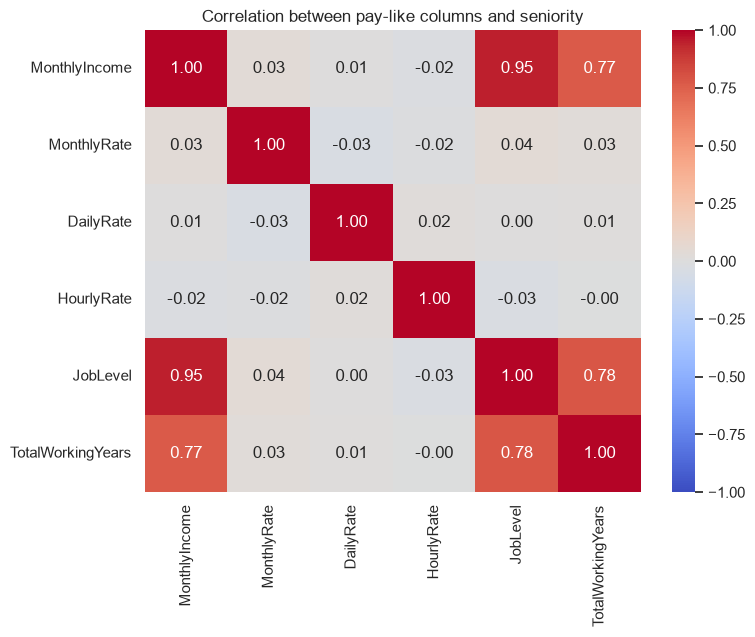

In [12]:
pay_columns = [
    "MonthlyIncome", "MonthlyRate", "DailyRate", "HourlyRate",
    "JobLevel", "TotalWorkingYears"
]

pay_corr = df[pay_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    pay_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation between pay-like columns and seniority")

plt.savefig(
    f"{FIG_DIR}/pay_columns_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** `MonthlyIncome` behaves like real pay. It rises strongly with job level
(correlation 0.95) and total working years (0.77). The three "Rate" columns are not
related to income, to each other, or to seniority (all correlations between −0.03 and
0.04), so their meaning is unclear. **EDA will therefore use `MonthlyIncome`
only.** The Rate columns are kept in the data; whether they are used in the models is a
modelling decision.

### 3.6 Summary and cleaning decisions

| Check | Result | Action |
|---|---|---|
| Missing values | None | None |
| Duplicates | None (checked ignoring the ID) | None |
| Value ranges and categories | Plausible and clean; units not documented | Compare results in relative terms |
| Constant columns | `EmployeeCount`, `Over18`, `StandardHours` | Drop |
| Identifier | `EmployeeNumber` | Drop |
| Pay columns | Only `MonthlyIncome` behaves like pay | Use `MonthlyIncome` for EDA; flag Rate columns for modelling |

The cleaned data is stored as `df_clean` and used in the rest of the notebook.

In [13]:
# Drop the constant columns and the identifier

columns_to_drop = constant_columns + ["EmployeeNumber"]

df_clean = df.drop(columns=columns_to_drop)

print("Dropped:", columns_to_drop)
print(f"Cleaned data: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns.")

Dropped: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Cleaned data: 1,470 rows and 31 columns.


## 4. Exploratory Data Analysis

Which factors are linked to employees leaving? The analysis is organised around the
hypotheses written **before** looking at the data. Each subsection tests one hypothesis
and ends with a finding. Charts compare leavers with stayers, using **attrition rates**
(the % of a group who left) rather than counts, because the groups differ in size.
These are associations, not causes.

| Section | Question |
|---|---|
| 4.1 Attrition distribution | How many employees left? (baseline for everything else) |
| 4.2 H1 Overtime | Do employees who work overtime leave more? |
| 4.3 H2 Pay | Is lower monthly income linked to leaving, even within the same job level? |
| 4.4 H3 Tenure and age | Do newer and younger employees leave more? |
| 4.5 H4 Satisfaction | Are low job/environment satisfaction and poor work-life balance linked to leaving? |
| 4.6 H5 Business travel | Do frequent travellers leave more? |
| 4.7 H6 Job role | Does attrition differ strongly by job role (and department)? |
| 4.8 H7 Gender and education (control) | Do these make little difference, as expected? |
| 4.9 Correlation overview | Which numeric variables are most linked to leaving? |
| 4.10 Hypothesis scorecard | Summary: supported, partly supported or not supported |

### 4.1 Attrition distribution

How many employees left? This overall rate is the baseline that every group is compared with.

In [14]:
# Number and percentage of employees who left (Yes) and stayed (No)

attrition_summary = pd.DataFrame({
    "Employees": df_clean["Attrition"].value_counts(),
    "Percentage (%)": (df_clean["Attrition"].value_counts(normalize=True) * 100).round(1)
})

attrition_summary

,Employees,Percentage (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


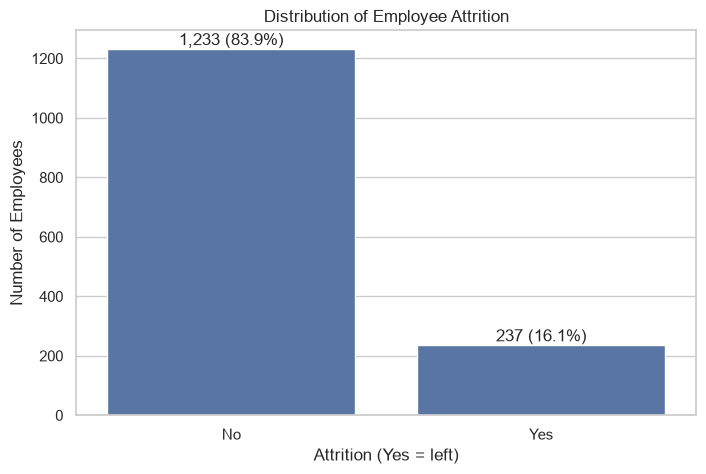

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="Attrition",
    order=["No", "Yes"]
)

# Label each bar with its count and percentage

total = len(df_clean)

for bar in ax.patches:
    count = int(bar.get_height())
    ax.annotate(
        f"{count:,} ({count / total:.1%})",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom"
    )

plt.title("Distribution of Employee Attrition")

plt.xlabel("Attrition (Yes = left)")

plt.ylabel("Number of Employees")

plt.savefig(
    f"{FIG_DIR}/attrition_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** 237 of 1,470 employees (16.1%) left, about 1 in 6. This 16.1% is the
baseline: a group with a clearly higher rate is at higher risk. The classes are
imbalanced: a model that predicts "stays" for everyone would be 84% accurate yet find
no leavers, so the models are judged on precision, recall and F1, not accuracy alone.
(The 16.1% is the share of leavers in this snapshot, not an annual turnover rate.)

### 4.4 H3: Tenure and age

*Work in progress:* the two age charts below come from the original EDA plan. The
tenure analysis and the finding will be added when we reach H3.

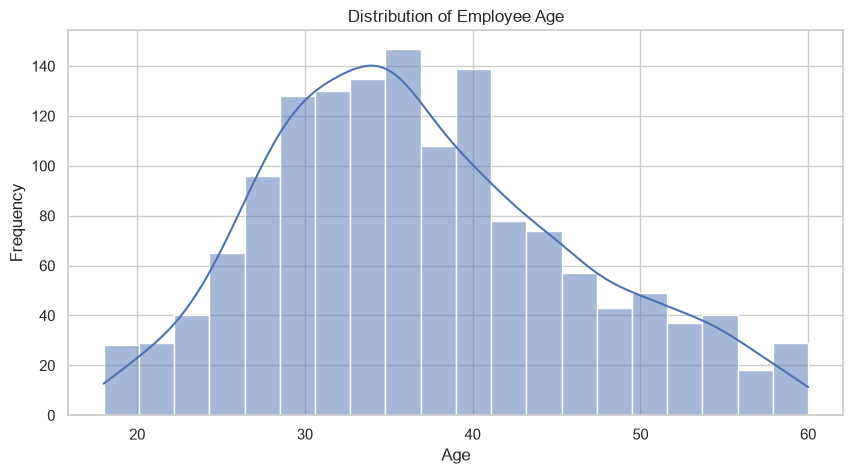

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Employee Age")

plt.xlabel("Age")

plt.ylabel("Frequency")

plt.savefig(
    f"{FIG_DIR}/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

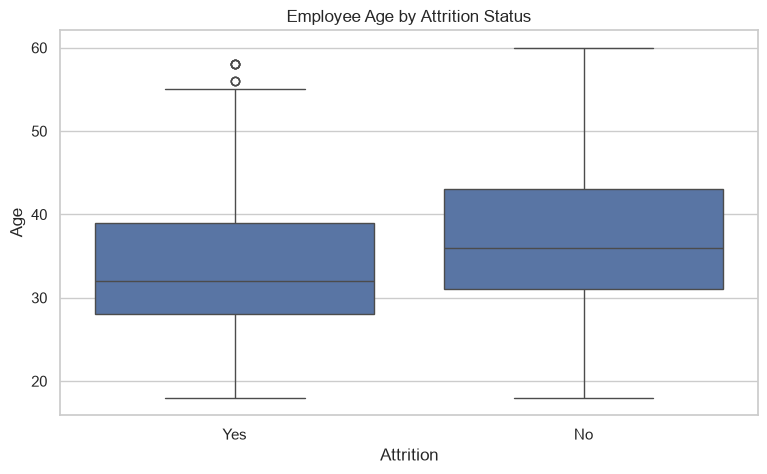

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="Age"
)

plt.title("Employee Age by Attrition Status")

plt.xlabel("Attrition")

plt.ylabel("Age")

plt.savefig(
    f"{FIG_DIR}/age_by_attrition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()